In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
data = pd.read_csv("customer_churn_dataset.csv")


In [4]:
print("First 5 rows of the dataset:")
print(data.head())


First 5 rows of the dataset:
  CustomerID  Gender  SeniorCitizen Partner Dependents  Tenure PhoneService  \
0   CUST1000    Male              0     Yes        Yes      23           No   
1   CUST1001    Male              1     Yes        Yes      68          Yes   
2   CUST1002  Female              1     Yes        Yes      60           No   
3   CUST1003    Male              1     Yes        Yes      30           No   
4   CUST1004    Male              0      No         No      28          Yes   

  InternetService        Contract PaperlessBilling     PaymentMethod  \
0             DSL  Month-to-month               No  Electronic check   
1             DSL        Two year              Yes       Credit card   
2              No        One year               No      Mailed check   
3     Fiber optic        One year               No      Mailed check   
4              No        One year               No     Bank transfer   

   MonthlyCharges Churn  
0           23.74    No  
1          

In [5]:
if 'customerID' in data.columns:
    data = data.drop('customerID', axis=1)


In [6]:
if 'TotalCharges' in data.columns:
    data['TotalCharges'] = pd.to_numeric(
        data['TotalCharges'], errors='coerce'
    )
    data['TotalCharges'] = data['TotalCharges'].fillna(
        data['TotalCharges'].median()
    )


In [8]:
encoder = LabelEncoder()

for column in data.select_dtypes(include='object').columns:
    data[column] = encoder.fit_transform(data[column])


In [9]:
X = data.drop('Churn', axis=1)
y = data['Churn']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [11]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)



In [12]:
model.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [13]:
y_pred = model.predict(X_test)

In [14]:
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")




Model Accuracy: 76.0 %


In [15]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.85      0.81        59
           1       0.74      0.63      0.68        41

    accuracy                           0.76       100
   macro avg       0.76      0.74      0.75       100
weighted avg       0.76      0.76      0.76       100



In [16]:
result = pd.DataFrame({
    'Actual': y_test.values[:10],
    'Predicted': y_pred[:10]
})
print("\nSample Predictions:")
print(result)




Sample Predictions:
   Actual  Predicted
0       0          1
1       0          0
2       1          1
3       1          1
4       0          1
5       0          0
6       0          0
7       0          0
8       1          1
9       1          1


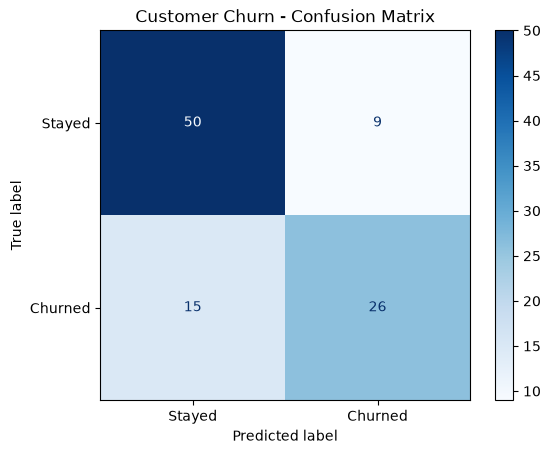

In [17]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stayed', 'Churned']
)

disp.plot(cmap='Blues')
plt.title("Customer Churn - Confusion Matrix")
plt.show()